In [1]:
import sys, torch
print(sys.executable)
print(torch.__version__, torch.version.cuda, torch.__file__)

c:\Users\Bala Ganesh\Documents\DL\Ass1\.venv\Scripts\python.exe
2.11.0+cu128 12.8 c:\Users\Bala Ganesh\Documents\DL\Ass1\.venv\Lib\site-packages\torch\__init__.py


In [2]:
import torch
print(torch.__version__, torch.cuda.is_available(), torch.cuda.get_device_name(0))

2.11.0+cu128 True NVIDIA GeForce RTX 3050 6GB Laptop GPU


In [3]:
import copy
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets

SEED = 42
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
OUT_DIR = Path("task1_outputs")
OUT_DIR.mkdir(exist_ok=True)

# Set QUICK = True for a fast smoke test (few epochs); False for the real runs.
QUICK = False
EPOCHS_FM = 3 if QUICK else 15       # Fashion-MNIST experiments
EPOCHS_CIFAR = 3 if QUICK else 25    # CIFAR-10 transfer
BATCH_SIZE = 128


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed()
print("device:", DEVICE)

device: cuda


In [4]:
class TensorLoader:
    """Minimal in-memory loader; data lives on DEVICE, so epochs are fast."""

    def __init__(self, x, y, batch_size, shuffle):
        self.x, self.y, self.bs, self.shuffle = x, y, batch_size, shuffle

    def __len__(self):
        return (len(self.x) + self.bs - 1) // self.bs

    def __iter__(self):
        n = len(self.x)
        idx = torch.randperm(n, device=self.x.device) if self.shuffle else torch.arange(n, device=self.x.device)
        for i in range(0, n, self.bs):
            b = idx[i:i + self.bs]
            yield self.x[b], self.y[b]


def _to_tensors(ds):
    x = torch.as_tensor(np.asarray(ds.data)).float() / 255.0
    x = x.unsqueeze(1) if x.ndim == 3 else x.permute(0, 3, 1, 2)  # -> N, C, H, W
    y = torch.as_tensor(np.array(ds.targets)).long()
    return x, y


def load_data(name, root="./data", val_frac=0.1, batch_size=BATCH_SIZE):
    cls = {"fashion": datasets.FashionMNIST, "cifar10": datasets.CIFAR10}[name]
    x_all, y_all = _to_tensors(cls(root, train=True, download=True))
    x_te, y_te = _to_tensors(cls(root, train=False, download=True))

    g = torch.Generator().manual_seed(SEED)
    perm = torch.randperm(len(x_all), generator=g)
    n_val = int(val_frac * len(x_all))
    val_idx, tr_idx = perm[:n_val], perm[n_val:]
    x_tr, y_tr, x_val, y_val = x_all[tr_idx], y_all[tr_idx], x_all[val_idx], y_all[val_idx]

    mean = x_tr.mean(dim=(0, 2, 3), keepdim=True)
    std = x_tr.std(dim=(0, 2, 3), keepdim=True)
    norm = lambda t: ((t - mean) / std).to(DEVICE)
    x_tr, x_val, x_te = norm(x_tr), norm(x_val), norm(x_te)
    y_tr, y_val, y_te = y_tr.to(DEVICE), y_val.to(DEVICE), y_te.to(DEVICE)

    return {
        "name": name,
        "in_shape": tuple(x_tr.shape[1:]),
        "train": TensorLoader(x_tr, y_tr, batch_size, shuffle=True),
        "val": TensorLoader(x_val, y_val, batch_size, shuffle=False),
        "test": TensorLoader(x_te, y_te, batch_size, shuffle=False),
        "sizes": (len(x_tr), len(x_val), len(x_te)),
    }


data_fm = load_data("fashion")
print("Fashion-MNIST", data_fm["in_shape"], "train/val/test:", data_fm["sizes"])

100.0%
100.0%
100.0%
100.0%
C:\RTemp\ipykernel_15352\4226094846.py:21: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  y = torch.as_tensor(np.array(ds.targets)).long()


Fashion-MNIST (1, 28, 28) train/val/test: (54000, 6000, 10000)


In [5]:
ACTS = {
    "relu": lambda: nn.ReLU(),
    "leaky_relu": lambda: nn.LeakyReLU(0.1),
    "gelu": lambda: nn.GELU(),
}


class MLP(nn.Module):
    def __init__(self, in_shape, n_classes=10, hidden=256, depth=2, act="relu", dropout=0.0):
        super().__init__()
        layers, d = [nn.Flatten()], int(np.prod(in_shape))
        for _ in range(depth):
            layers += [nn.Linear(d, hidden), ACTS[act](), nn.Dropout(dropout)]
            d = hidden
        layers.append(nn.Linear(d, n_classes))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


class CNN(nn.Module):
    """[Conv(k) -> act -> MaxPool(2)] x len(channels) -> Flatten -> Linear(fc) -> act -> Dropout -> Linear."""

    def __init__(self, in_shape, n_classes=10, channels=(32, 64), kernel=3, fc=128, act="relu", dropout=0.0):
        super().__init__()
        c, h, w = in_shape
        layers = []
        for ch in channels:
            layers += [nn.Conv2d(c, ch, kernel, padding=kernel // 2), ACTS[act](), nn.MaxPool2d(2)]
            c, h, w = ch, h // 2, w // 2
        layers += [nn.Flatten(), nn.Linear(c * h * w, fc), ACTS[act](), nn.Dropout(dropout),
                   nn.Linear(fc, n_classes)]
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


def init_weights(model, scheme):
    """Apply an initialisation scheme (torch.nn.init) to all Linear/Conv2d layers."""
    if scheme == "default":  # PyTorch's own default (Kaiming-uniform with a=sqrt(5))
        return
    for m in model.modules():
        if isinstance(m, (nn.Linear, nn.Conv2d)):
            if scheme == "xavier":
                nn.init.xavier_uniform_(m.weight)
            elif scheme == "kaiming":
                nn.init.kaiming_normal_(m.weight, nonlinearity="relu")
            elif scheme == "normal":
                nn.init.normal_(m.weight, mean=0.0, std=0.02)
            elif scheme == "zeros":  # deliberately bad: symmetry is never broken
                nn.init.zeros_(m.weight)
            else:
                raise ValueError(scheme)
            nn.init.zeros_(m.bias)


def make_model(cfg, in_shape):
    if cfg["model"] == "mlp":
        m = MLP(in_shape, hidden=cfg["hidden"], depth=cfg["depth"], act=cfg["act"], dropout=cfg["dropout"])
    else:
        m = CNN(in_shape, channels=cfg["channels"], kernel=cfg["kernel"], fc=cfg["fc"],
                act=cfg["act"], dropout=cfg["dropout"])
    init_weights(m, cfg["init"])
    return m.to(DEVICE)


def make_optimizer(params, name, lr, wd):
    if name == "sgd":
        return torch.optim.SGD(params, lr=lr, momentum=0.9, weight_decay=wd)
    if name == "adam":
        return torch.optim.Adam(params, lr=lr, weight_decay=wd)
    if name == "adamw":
        return torch.optim.AdamW(params, lr=lr, weight_decay=wd)
    raise ValueError(name)

In [6]:
@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    loss_sum, correct, n = 0.0, 0, 0
    for x, y in loader:
        out = model(x)
        loss_sum += F.cross_entropy(out, y, reduction="sum").item()
        correct += (out.argmax(1) == y).sum().item()
        n += len(y)
    return loss_sum / n, correct / n


def fit(model, train_loader, val_loader, optimizer, epochs):
    hist = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best_acc, best_state, best_epoch = -1.0, None, -1
    for ep in range(epochs):
        model.train()
        loss_sum, correct, n = 0.0, 0, 0
        for x, y in train_loader:
            optimizer.zero_grad()
            out = model(x)
            loss = F.cross_entropy(out, y)
            loss.backward()
            optimizer.step()
            loss_sum += loss.item() * len(y)
            correct += (out.argmax(1) == y).sum().item()
            n += len(y)
        val_loss, val_acc = evaluate(model, val_loader)
        hist["train_loss"].append(loss_sum / n)
        hist["train_acc"].append(correct / n)
        hist["val_loss"].append(val_loss)
        hist["val_acc"].append(val_acc)
        if val_acc > best_acc:
            best_acc, best_epoch = val_acc, ep
            best_state = copy.deepcopy(model.state_dict())
    model.load_state_dict(best_state)
    return hist, best_acc, best_epoch


def run_experiment(cfg, data, epochs, keep_model=False):
    """Train one configuration from a fixed seed. Returns a result dict."""
    set_seed(SEED)
    model = make_model(cfg, data["in_shape"])
    opt = make_optimizer(model.parameters(), cfg["opt"], cfg["lr"], cfg["wd"])
    t0 = time.time()
    hist, best_val, best_ep = fit(model, data["train"], data["val"], opt, epochs)
    res = {
        "model": cfg["model"],
        "val_acc": best_val,
        "best_epoch": best_ep + 1,
        "train_acc_at_best": hist["train_acc"][best_ep],
        "gap": hist["train_acc"][best_ep] - best_val,
        "n_params": sum(p.numel() for p in model.parameters()),
        "time_s": time.time() - t0,
        "cfg": cfg,
        "hist": hist,
    }
    if keep_model:
        res["torch_model"] = model
    return res

In [7]:
BASE = {
    "mlp": dict(model="mlp", hidden=256, depth=2, act="relu", init="default",
                opt="adam", lr=1e-3, wd=0.0, dropout=0.0),
    "cnn": dict(model="cnn", channels=(32, 64), kernel=3, fc=128, act="relu", init="default",
                opt="adam", lr=1e-3, wd=0.0, dropout=0.0),
}

COMMON_FACTORS = {
    "init": [dict(init=v) for v in ["default", "xavier", "kaiming", "normal", "zeros"]],
    "activation": [dict(act=v) for v in ["relu", "leaky_relu", "gelu"]],
    "optimizer": [
        dict(opt="sgd", lr=0.01), dict(opt="sgd", lr=0.1),
        dict(opt="adam", lr=1e-3), dict(opt="adam", lr=1e-2),
        dict(opt="adamw", lr=1e-3, wd=0.01), dict(opt="adamw", lr=1e-2, wd=0.01),
    ],
    "regularization": [
        dict(dropout=0.25), dict(dropout=0.5),
        dict(wd=1e-4), dict(wd=1e-3),
        dict(dropout=0.25, wd=1e-4),
    ],
}
ARCH_FACTORS = {
    "mlp": [dict(depth=d, hidden=w) for d in (1, 2, 3, 4) for w in (128, 256, 512)],
    "cnn": [dict(channels=c, kernel=k, fc=f)
            for c, k, f in [((16, 32), 3, 128), ((32, 64), 3, 128), ((64, 128), 3, 128),
                            ((32, 64, 128), 3, 128), ((32, 64), 5, 128), ((32, 64), 3, 256),
                            ((32,), 3, 128)]],
}


def factor_grid(model_name):
    grid = dict(COMMON_FACTORS)
    grid["architecture"] = ARCH_FACTORS[model_name]
    return grid


def describe(override, base):
    return ", ".join(f"{k}={v}" for k, v in override.items() if base.get(k) != v) or "baseline"


def run_grid(model_name, data, epochs):
    base = BASE[model_name]
    rows = []
    cache = {}  # identical configs are trained once
    for factor, variants in factor_grid(model_name).items():
        for ov in variants:
            cfg = {**base, **ov}
            key = repr(sorted(cfg.items()))
            if key not in cache:
                cache[key] = run_experiment(cfg, data, epochs)
                r = cache[key]
                print(f"[{model_name}] {factor:<14} {describe(ov, base):<40} "
                      f"val_acc={r['val_acc']:.4f} gap={r['gap']:+.3f}")
            rows.append({**cache[key], "factor": factor, "name": describe(ov, base), "override": ov})
    return rows


def combine_best(model_name, rows, data, epochs):
    """Merge the best override of every factor into one configuration and train it."""
    base, merged = BASE[model_name], {}
    for factor in factor_grid(model_name):
        best = max((r for r in rows if r["factor"] == factor), key=lambda r: r["val_acc"])
        merged.update(best["override"])
    cfg = {**base, **merged}
    r = run_experiment(cfg, data, epochs)
    print(f"[{model_name}] COMBINED {describe(merged, base)} -> val_acc={r['val_acc']:.4f}")
    return {**r, "factor": "combined", "name": describe(merged, base), "override": merged}

In [8]:
all_rows = {}
for m in ("mlp", "cnn"):
    rows = run_grid(m, data_fm, EPOCHS_FM)
    rows.append(combine_best(m, rows, data_fm, EPOCHS_FM))
    all_rows[m] = rows

[mlp] init           baseline                                 val_acc=0.8968 gap=+0.040
[mlp] init           init=xavier                              val_acc=0.8972 gap=+0.044
[mlp] init           init=kaiming                             val_acc=0.8978 gap=+0.045
[mlp] init           init=normal                              val_acc=0.8945 gap=+0.048
[mlp] init           init=zeros                               val_acc=0.0980 gap=+0.002
[mlp] activation     act=leaky_relu                           val_acc=0.8970 gap=+0.036
[mlp] activation     act=gelu                                 val_acc=0.8960 gap=+0.055
[mlp] optimizer      opt=sgd, lr=0.01                         val_acc=0.8925 gap=+0.037
[mlp] optimizer      opt=sgd, lr=0.1                          val_acc=0.8823 gap=+0.038
[mlp] optimizer      lr=0.01                                  val_acc=0.8738 gap=+0.005
[mlp] optimizer      opt=adamw, wd=0.01                       val_acc=0.8947 gap=+0.047
[mlp] optimizer      opt=adamw, 

In [9]:
def to_df(rows):
    keep = ["model", "factor", "name", "val_acc", "best_epoch", "train_acc_at_best", "gap", "n_params", "time_s"]
    return pd.DataFrame([{k: r[k] for k in keep} for r in rows])


df_all = pd.concat([to_df(all_rows[m]) for m in all_rows], ignore_index=True)
df_all.to_csv(OUT_DIR / "fashion_mnist_experiments.csv", index=False)

for m in all_rows:
    for factor, g in df_all[df_all.model == m].groupby("factor", sort=False):
        print(f"\n=== {m.upper()} | {factor} ===")
        print(g[["name", "val_acc", "train_acc_at_best", "gap", "n_params"]]
              .to_string(index=False, float_format=lambda v: f"{v:.4f}"))


=== MLP | init ===
        name  val_acc  train_acc_at_best    gap  n_params
    baseline   0.8968             0.9364 0.0396    269322
 init=xavier   0.8972             0.9416 0.0444    269322
init=kaiming   0.8978             0.9431 0.0453    269322
 init=normal   0.8945             0.9424 0.0479    269322
  init=zeros   0.0980             0.1002 0.0022    269322

=== MLP | activation ===
          name  val_acc  train_acc_at_best    gap  n_params
      baseline   0.8968             0.9364 0.0396    269322
act=leaky_relu   0.8970             0.9327 0.0357    269322
      act=gelu   0.8960             0.9506 0.0546    269322

=== MLP | optimizer ===
                       name  val_acc  train_acc_at_best    gap  n_params
           opt=sgd, lr=0.01   0.8925             0.9299 0.0374    269322
            opt=sgd, lr=0.1   0.8823             0.9199 0.0376    269322
                   baseline   0.8968             0.9364 0.0396    269322
                    lr=0.01   0.8738             

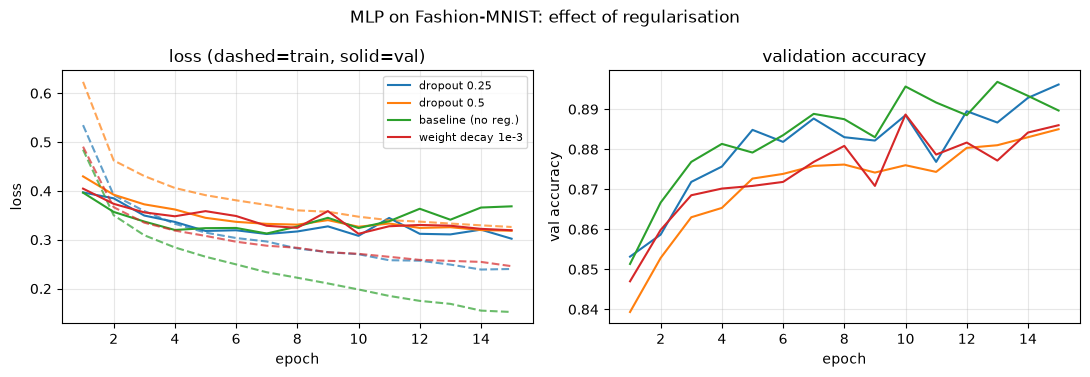

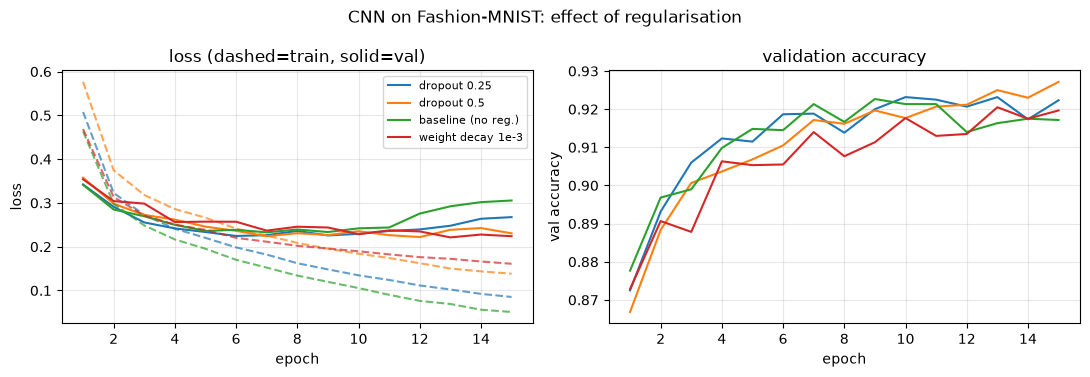

In [10]:
def find(rows, factor, name):
    return next(r for r in rows if r["factor"] == factor and r["name"] == name)


def plot_curves(results, labels, title, fname):
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
    for r, lab in zip(results, labels):
        ep = np.arange(1, len(r["hist"]["val_acc"]) + 1)
        l, = axes[0].plot(ep, r["hist"]["train_loss"], ls="--", alpha=.7)
        axes[0].plot(ep, r["hist"]["val_loss"], color=l.get_color(), label=lab)
        axes[1].plot(ep, r["hist"]["val_acc"], color=l.get_color(), label=lab)
    axes[0].set(xlabel="epoch", ylabel="loss", title="loss (dashed=train, solid=val)")
    axes[1].set(xlabel="epoch", ylabel="val accuracy", title="validation accuracy")
    for a in axes:
        a.grid(alpha=.3)
    axes[0].legend(fontsize=8)
    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(OUT_DIR / fname, dpi=200)
    plt.show()


for m in ("mlp", "cnn"):
    rows = all_rows[m]
    sel = [find(rows, "regularization", "dropout=0.25"), find(rows, "regularization", "dropout=0.5"),
           find(rows, "init", "baseline"), find(rows, "regularization", "wd=0.001")]
    plot_curves(sel, ["dropout 0.25", "dropout 0.5", "baseline (no reg.)", "weight decay 1e-3"],
                f"{m.upper()} on Fashion-MNIST: effect of regularisation", f"curves_{m}_regularization.png")

In [11]:
def select_top3(rows_by_model):
    flat = [r for rows in rows_by_model.values() for r in rows]
    best_mlp = max((r for r in flat if r["model"] == "mlp"), key=lambda r: r["val_acc"])
    best_cnn = max((r for r in flat if r["model"] == "cnn"), key=lambda r: r["val_acc"])
    rest = [r for r in flat if r is not best_mlp and r is not best_cnn
            and repr(sorted(r["cfg"].items())) not in
            {repr(sorted(best_mlp["cfg"].items())), repr(sorted(best_cnn["cfg"].items()))}]
    third = max(rest, key=lambda r: r["val_acc"])
    return [best_mlp, best_cnn, third]


top3 = select_top3(all_rows)
for i, r in enumerate(top3, 1):
    print(f"#{i} {r['model'].upper()} [{r['factor']}: {r['name']}] val_acc={r['val_acc']:.4f}\n    {r['cfg']}")

#1 MLP [architecture: depth=3] val_acc=0.9003
    {'model': 'mlp', 'hidden': 256, 'depth': 3, 'act': 'relu', 'init': 'default', 'opt': 'adam', 'lr': 0.001, 'wd': 0.0, 'dropout': 0.0}
#2 CNN [architecture: channels=(64, 128)] val_acc=0.9278
    {'model': 'cnn', 'channels': (64, 128), 'kernel': 3, 'fc': 128, 'act': 'relu', 'init': 'default', 'opt': 'adam', 'lr': 0.001, 'wd': 0.0, 'dropout': 0.0}
#3 CNN [regularization: dropout=0.5] val_acc=0.9272
    {'model': 'cnn', 'channels': (32, 64), 'kernel': 3, 'fc': 128, 'act': 'relu', 'init': 'default', 'opt': 'adam', 'lr': 0.001, 'wd': 0.0, 'dropout': 0.5}


In [12]:
data_c10 = load_data("cifar10")
print("CIFAR-10", data_c10["in_shape"], "train/val/test:", data_c10["sizes"])

final_rows, final_hist = [], {}
for i, r in enumerate(top3, 1):
    tag = f"cfg{i}_{r['model']}"
    for ds_name, data, ep in (("Fashion-MNIST", data_fm, EPOCHS_FM), ("CIFAR-10", data_c10, EPOCHS_CIFAR)):
        res = run_experiment(r["cfg"], data, ep, keep_model=True)
        _, test_acc = evaluate(res["torch_model"], data["test"])
        final_rows.append({"config": tag, "dataset": ds_name, "val_acc": res["val_acc"],
                           "test_acc": test_acc, "train_acc": res["train_acc_at_best"],
                           "gap": res["gap"], "n_params": res["n_params"]})
        final_hist[(tag, ds_name)] = res
        print(f"{tag:<10} {ds_name:<14} val={res['val_acc']:.4f} test={test_acc:.4f}")

df_final = pd.DataFrame(final_rows)
df_final.to_csv(OUT_DIR / "final_comparison.csv", index=False)
print()
print(df_final.to_string(index=False, float_format=lambda v: f"{v:.4f}"))

# Side-by-side table (Fashion-MNIST vs CIFAR-10) and accuracy drop
side = df_final.pivot(index="config", columns="dataset", values="test_acc")
side["drop"] = side["Fashion-MNIST"] - side["CIFAR-10"]
print("\nTest accuracy side by side:")
print(side.to_string(float_format=lambda v: f"{v:.4f}"))
side.to_csv(OUT_DIR / "side_by_side_test_acc.csv")

100.0%


CIFAR-10 (3, 32, 32) train/val/test: (45000, 5000, 10000)
cfg1_mlp   Fashion-MNIST  val=0.9003 test=0.8943
cfg1_mlp   CIFAR-10       val=0.5418 test=0.5384
cfg2_cnn   Fashion-MNIST  val=0.9257 test=0.9213
cfg2_cnn   CIFAR-10       val=0.7416 test=0.7322
cfg3_cnn   Fashion-MNIST  val=0.9260 test=0.9205
cfg3_cnn   CIFAR-10       val=0.7442 test=0.7393

  config       dataset  val_acc  test_acc  train_acc    gap  n_params
cfg1_mlp Fashion-MNIST   0.9003    0.8943     0.9410 0.0407    335114
cfg1_mlp      CIFAR-10   0.5418    0.5384     0.6961 0.1543    920842
cfg2_cnn Fashion-MNIST   0.9257    0.9213     0.9901 0.0645    878730
cfg2_cnn      CIFAR-10   0.7416    0.7322     0.8221 0.0805   1125642
cfg3_cnn Fashion-MNIST   0.9260    0.9205     0.9476 0.0216    421642
cfg3_cnn      CIFAR-10   0.7442    0.7393     0.8023 0.0581    545098

Test accuracy side by side:
dataset   CIFAR-10  Fashion-MNIST   drop
config                                  
cfg1_mlp    0.5384         0.8943 0.3559
cfg2_

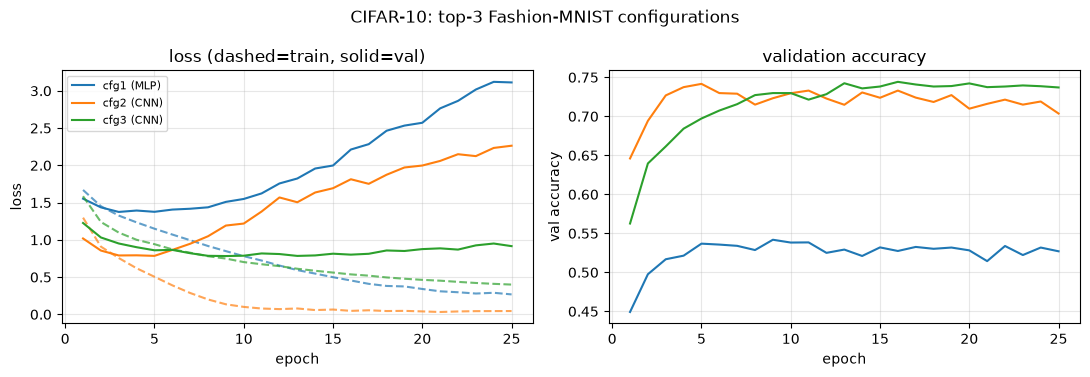

In [13]:
# CIFAR-10 learning curves of the 3 configurations (shows stronger overfitting for MLPs)
res_c10 = [final_hist[(f"cfg{i}_{r['model']}", "CIFAR-10")] for i, r in enumerate(top3, 1)]
plot_curves(res_c10, [f"cfg{i} ({r['model'].upper()})" for i, r in enumerate(top3, 1)],
            "CIFAR-10: top-3 Fashion-MNIST configurations", "curves_cifar10_top3.png")